# Local rSFMS excess fractions by infall stage

24 November 2026 · MAUVE Paper II

[Method C in the discussion](https://chatgpt.com/c/6b04ea3e-a484-83ec-9617-4870f9532aab) reduces the threshold curves to one fraction per galaxy. This version compares **four thresholds from one to four pre-peak widths** and includes all selected SF spaxels at every stellar surface density. The comparison uses the Paper II 7000 products, with the original cell 44 and 45 figures reproduced below.

For each selected SF spaxel, $\Delta=\log_{10}\Sigma_{\rm SFR}-\log_{10}\Sigma_{\rm SFR,pre}(\Sigma_*)$ in dex. The Paper II normalization gives $E=\Delta/W$, so $\Delta>kW$ is equivalent to $E>k$, for $k=1,2,3,4$. The pre-peak fit gives each galaxy unit total weight. The width $W$ averages, across pre-peak galaxies, their mean $\sqrt{\max(\Delta^2-\sigma_{\rm dex}^2,0)}$ over spaxels with valid corrected H$\alpha$ flux errors.

In each panel, one point per galaxy gives $N_{\rm SF}(\Delta>kW)/N_{\rm SF}$ for one galaxy. Both counts use the Paper II SF selection. The shared straight-line fit is extrapolated where needed. The pre-peak band shows the 16th–84th percentiles across pre-peak galaxy fractions. Each stage mean weights its galaxies equally. The fractions describe how common high local SFR surface densities are within the selected SF footprint, relative to the pre-peak relation at the same stellar surface density.

The panels use logarithmic percentage axes with different limits. Each galaxy keeps the same horizontal position across thresholds. Open circles centered on the x-axis baseline mark galaxies with zero spaxels above the threshold.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}

# Use the same palette for every plot that identifies individual galaxies.
GALAXY_COLORS = {}
for palette_line in (PROJECT_ROOT / 'MAUVE_galaxy_colors.dat').read_text().splitlines():
    if not palette_line.strip() or palette_line.lstrip().startswith('#'):
        continue
    fields = palette_line.split()
    if fields[1] != 'TOTAL_ASSEMBLED':
        GALAXY_COLORS[fields[1]] = fields[3]

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 22, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')


def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return 0.0
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    for name in ('LOGSFR_SURFACE_DENSITY', 'LOGSFR_SURFACE_DENSITY_HII',
                 'LOGSFR_SURFACE_DENSITY_UPPER'):
        gas_arrays[name] += delta
    return delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths

sf_x_parts, sf_y_parts, sf_error_parts, sf_group_parts = [], [], [], []
inventory_rows, count_rows = [], []
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,product_id=product_id,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR',
            'HA6562_FLUX_CORR', 'HA6562_FLUX_ERR_CORR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    density_log10_shift = apply_component_inclination(product_id, component, mass, arrays)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))
    group_id = len(count_rows)
    sf_group_parts.append(np.full(int(sf.sum()), group_id, dtype=np.int16))
    sf_x_parts.append(mass[sf])
    sf_y_parts.append(sfr[sf])
    # Paired Halpha errors for the source excess-width recipe, in the same SF order.
    ha_flux_sf = arrays['HA6562_FLUX_CORR'][sf]
    ha_error_sf = arrays['HA6562_FLUX_ERR_CORR'][sf]
    ha_error_ok = np.isfinite(ha_flux_sf) & (ha_flux_sf > 0) & np.isfinite(ha_error_sf) & (ha_error_sf >= 0)
    sf_error_dex = np.full(len(ha_flux_sf), np.nan)
    sf_error_dex[ha_error_ok] = ha_error_sf[ha_error_ok] / ha_flux_sf[ha_error_ok] / np.log(10.0)
    sf_error_parts.append(sf_error_dex)
    count_rows.append(dict(galaxy=gal,product_id=product_id,stage=meta['stage'],inclination=meta['inclination'], before_SNR_cut=int(pre_snr.sum()),
        rejected_SNR=int((pre_snr & ~snr_pass).sum()), usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()),
        ND_invalid=int((nd & ~measurable).sum()), NSF=int(nsf.sum()),
        CUT_SN=sn_cut, NOISE=floor, density_log10_shift=density_log10_shift))

inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
assert (counts.before_SNR_cut == counts.rejected_SNR+counts.usable).all()
assert counts.inclination.lt(80.0).all()
if not sf_x_parts or not counts.SF.sum():
    raise RuntimeError('No selected SF detections from complete Paper II products')

sf_x, sf_y, sf_group = map(np.concatenate, (sf_x_parts, sf_y_parts, sf_group_parts))
assert len(sf_x) == len(sf_y) == len(sf_group) == counts.SF.sum()
assert np.array_equal(np.bincount(sf_group, minlength=len(counts)), counts.SF)
excluded_products = inventory.loc[inventory.status.ne('included'), ['galaxy', 'stage', 'status']]
if not excluded_products.empty:
    display(excluded_products.reset_index(drop=True))
print(f'{len(counts)} galaxies with complete products; {len(sf_x):,} selected SF spaxels')

,galaxy,stage,status
0,NGC4192,1,excluded: inclination >=80 or unavailable
1,NGC4216,3,excluded: inclination >=80 or unavailable
2,NGC4222,1,excluded: inclination >=80 or unavailable
3,NGC4302,2,excluded: inclination >=80 or unavailable
4,NGC4321,1,missing: gas
5,NGC4330,2,excluded: inclination >=80 or unavailable
6,NGC4388,2,excluded: inclination >=80 or unavailable
7,NGC4396,1,excluded: inclination >=80 or unavailable
8,NGC4402,2,excluded: inclination >=80 or unavailable
9,NGC4522,2,excluded: inclination >=80 or unavailable


29 galaxies with complete products; 2,369,094 selected SF spaxels


In [3]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])

sf_stage = counts.stage.to_numpy(int)[sf_group]
pre = sf_stage == 1
pre_peak_fit = equal_galaxy_ols(sf_x[pre], sf_y[pre], sf_group[pre])
excess_meta = counts.reset_index(drop=True)

excess_errors = np.concatenate(sf_error_parts)
assert len(excess_errors) == len(sf_x) == len(sf_y) == len(sf_group)
excess_reference = pre_peak_fit['slope'] * sf_x + pre_peak_fit['intercept']
excess_residuals = sf_y - excess_reference
excess_pre_ids = excess_meta.index[(excess_meta.stage == 1) & (excess_meta.SF > 0)].to_numpy()
assert len(excess_pre_ids), 'No pre-peak SF reference products'
excess_width_rows = []
for group_id in excess_pre_ids:
    selected = (sf_group == group_id) & np.isfinite(excess_errors) & (excess_errors >= 0)
    assert selected.any(), f'{excess_meta.loc[group_id, "galaxy"]}: no finite errors for width'
    radicand = excess_residuals[selected]**2 - excess_errors[selected]**2
    excess_width_rows.append(dict(galaxy=excess_meta.loc[group_id, 'galaxy'],
        N_width=int(selected.sum()), width_dex=float(np.sqrt(np.maximum(radicand, 0)).mean()),
        fraction_clipped_to_zero=float((radicand <= 0).mean())))
excess_width_by_galaxy = pd.DataFrame(excess_width_rows)
excess_width = float(excess_width_by_galaxy.width_dex.mean())
assert np.isfinite(excess_width) and excess_width > 0
excess_values = excess_residuals / excess_width
print(f"Pre-peak rSFMS: y = {pre_peak_fit['slope']:.6f}x {pre_peak_fit['intercept']:+.6f}")
print(f'W = {excess_width:.6f} dex ({10 ** excess_width:.2f} times the reference)')

Pre-peak rSFMS: y = 0.760330x -8.078989
W = 0.392265 dex (2.47 times the reference)


In [4]:
width_multiples = (1, 2, 3, 4)
galaxy_sample = counts[['galaxy', 'stage', 'SF']].rename(columns={'SF': 'N_SF'})
fraction_tables = []
for multiple in width_multiples:
    above_threshold = excess_values > multiple
    sample = galaxy_sample.assign(
        multiple=multiple,
        N_above=np.bincount(sf_group[above_threshold], minlength=len(galaxy_sample)),
    )
    sample['fraction'] = sample.N_above / sample.N_SF.where(sample.N_SF > 0)
    fraction_tables.append(sample)

by_galaxy = pd.concat(fraction_tables, ignore_index=True)
assert by_galaxy.N_above.le(by_galaxy.N_SF).all()
assert by_galaxy.fraction.dropna().between(0, 1).all()
counts_by_threshold = by_galaxy.pivot(index='galaxy', columns='multiple', values='N_above')
assert (np.diff(counts_by_threshold, axis=1) <= 0).all()

stage_summary = by_galaxy.groupby(['multiple', 'stage']).agg(
    N_galaxies=('fraction', 'count'),
    mean=('fraction', 'mean'),
    p16=('fraction', lambda f: f.quantile(0.16)),
    p84=('fraction', lambda f: f.quantile(0.84)),
)
assert set(stage_summary.index.get_level_values('stage')) == set(STAGE_LABELS)
assert stage_summary.N_galaxies.gt(0).all()
pre_peak_p84 = stage_summary.xs(1, level='stage').p84
by_galaxy['above_pre_p84'] = by_galaxy.fraction.gt(by_galaxy.multiple.map(pre_peak_p84))
stage_summary['N_above_pre_p84'] = by_galaxy.groupby(['multiple', 'stage']).above_pre_p84.sum()

display(stage_summary.rename(index=STAGE_LABELS, level='stage').style.format(
    {name: '{:.2%}' for name in ('mean', 'p16', 'p84')}))
galaxy_fractions = by_galaxy.pivot(index=['stage', 'galaxy', 'N_SF'], columns='multiple', values='fraction')
galaxy_fractions = galaxy_fractions.sort_values(['stage', 1], ascending=[True, False])
galaxy_fractions = galaxy_fractions.rename(index=STAGE_LABELS, level='stage')
display(galaxy_fractions.rename(columns={k: f'> {k}W' for k in width_multiples})
    .style.format('{:.2%}', na_rep='n/a'))

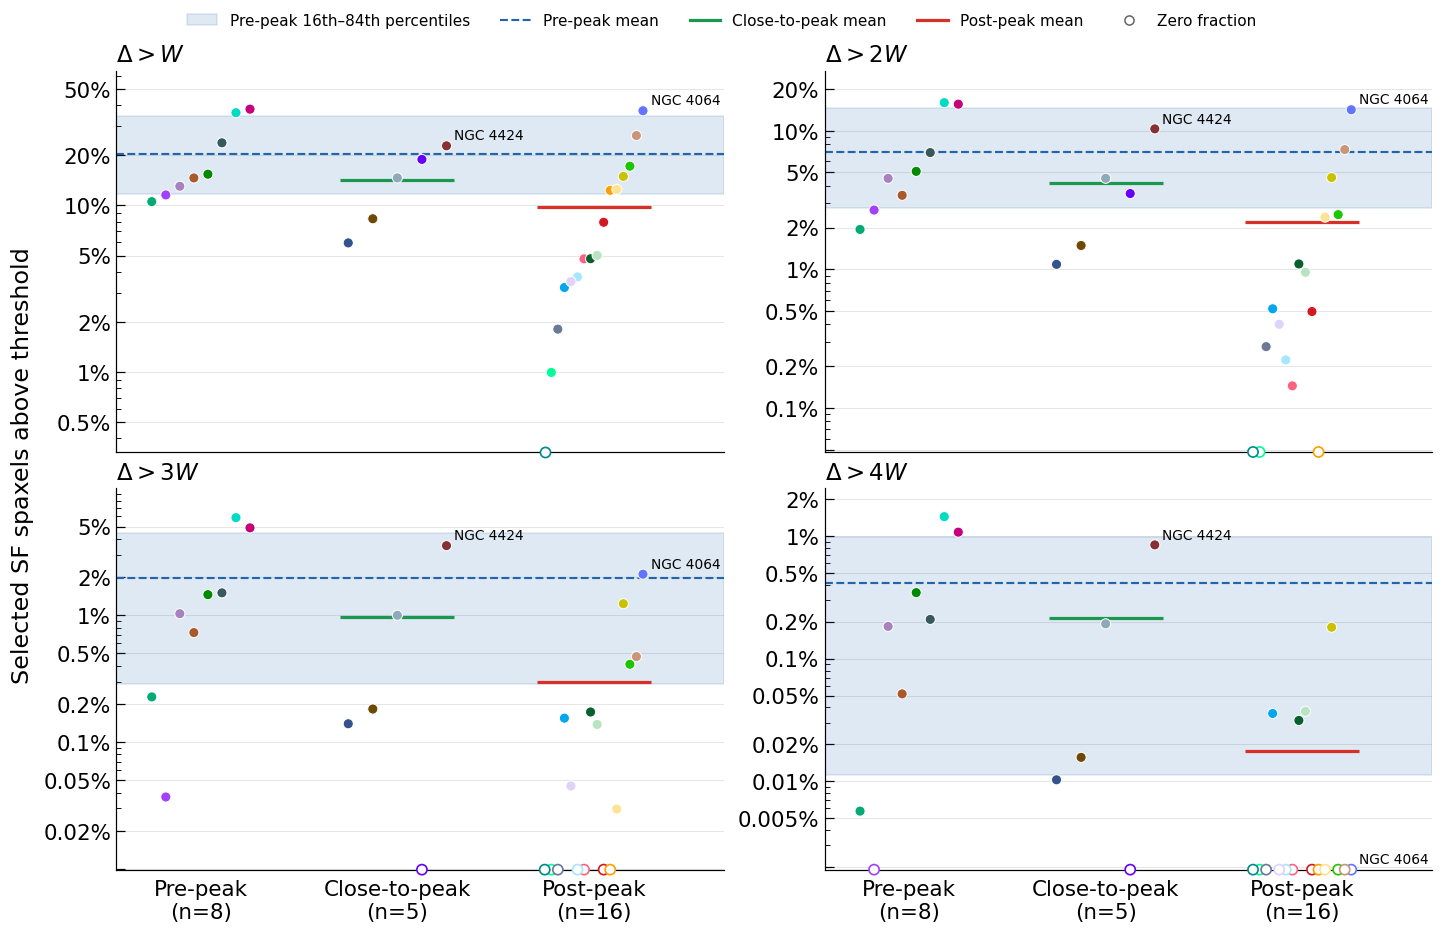

In [5]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

plotted = by_galaxy.dropna(subset=['fraction']).copy()
assert set(plotted.galaxy) <= GALAXY_COLORS.keys()
positions = {}
for stage, sample in plotted.loc[plotted.multiple.eq(1)].groupby('stage'):
    sample = sample.sort_values(['fraction', 'galaxy'])
    offsets = np.linspace(-0.25, 0.25, len(sample)) if len(sample) > 1 else [0.]
    positions.update(zip(sample.galaxy, stage + np.asarray(offsets)))
plotted['position'] = plotted.galaxy.map(positions)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.4), sharex=True, layout='constrained')
for multiple, ax in zip(width_multiples, axes.flat):
    summary = stage_summary.loc[multiple]
    pre_peak = summary.loc[1]
    band = ax.axhspan(pre_peak.p16, pre_peak.p84, color=STAGE_COLORS[1], alpha=0.14)
    pre_line = ax.axhline(pre_peak['mean'], color=STAGE_COLORS[1], ls='--', lw=1.4)
    sample = plotted.loc[plotted.multiple.eq(multiple)]
    positive = sample.fraction.gt(0)
    detected = sample.loc[positive]
    zeros = sample.loc[~positive]
    zero_baseline = 0.0
    ax.scatter(detected.position, detected.fraction, s=44, zorder=4,
               facecolors=detected.galaxy.map(GALAXY_COLORS),
               edgecolors='white', linewidths=0.65)
    ax.scatter(zeros.position, np.full(len(zeros), zero_baseline), s=44, zorder=4,
               transform=ax.get_xaxis_transform(), clip_on=False, facecolors='white',
               edgecolors=zeros.galaxy.map(GALAXY_COLORS), linewidths=1.1)
    for stage in (2, 3):
        ax.hlines(summary.loc[stage, 'mean'], stage - 0.29, stage + 0.29,
                  color=STAGE_COLORS[stage], lw=2.1, zorder=3)
    for row in sample.loc[sample.galaxy.isin(['NGC4424', 'NGC4064'])].itertuples():
        xy = (row.position, row.fraction if row.fraction > 0 else zero_baseline)
        coordinates = ax.transData if row.fraction > 0 else ax.get_xaxis_transform()
        ax.annotate(row.galaxy.replace('NGC', 'NGC '), xy, xycoords=coordinates,
                    xytext=(5, 4), textcoords='offset points', fontsize=9, zorder=5)

    peak = detected.fraction.max() if len(detected) else 0.01
    floor = detected.fraction.min() / 3 if len(detected) else 0.001
    if pre_peak.p16 > 0:
        floor = min(floor, pre_peak.p16 / 2)
    ax.set(yscale='log', xlim=(0.57, 3.66), ylim=(floor, min(1, 1.7 * peak)))
    ax.set_title(rf'$\Delta > {"" if multiple == 1 else multiple}W$', loc='left', fontsize=15)
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5), numticks=12))
    # Leave clear space between the zero marker row and the first labeled log tick.
    lower, upper = ax.get_ylim()
    label_floor = lower * (upper / lower) ** 0.06
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda f, _, limit=label_floor: f'{100 * f:g}%' if f >= limit else ''))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis='x', length=0, pad=6)
    ax.grid(axis='y', color='0.9', lw=0.7)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

labels = [f'{name}\n(n={stage_summary.loc[(1, stage), "N_galaxies"]})'
          for stage, name in STAGE_LABELS.items()]
for ax in axes[-1]:
    ax.set_xticks(list(STAGE_LABELS), labels)
fig.supylabel('Selected SF spaxels above threshold')
fig.legend([band, pre_line, Line2D([], [], color=STAGE_COLORS[2], lw=2.1),
            Line2D([], [], color=STAGE_COLORS[3], lw=2.1),
            Line2D([], [], marker='o', ls='', color='0.4', markerfacecolor='white')],
           ['Pre-peak 16th–84th percentiles', 'Pre-peak mean', 'Close-to-peak mean', 'Post-peak mean', 'Zero fraction'],
           loc='outside upper center', ncols=5, fontsize=10, frameon=False)
plt.show()

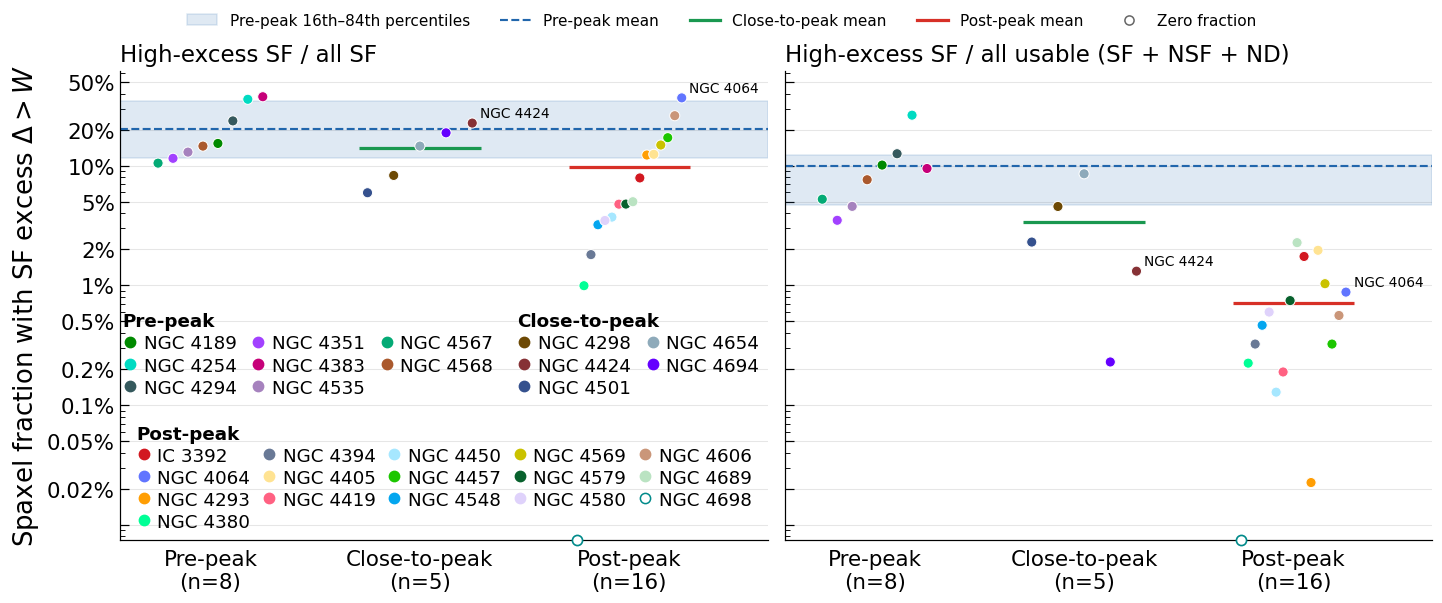

In [6]:
# One numerator per galaxy: selected SF spaxels with Delta > W.
# The usable footprint retains the Paper II spatial mask and strict SNR_POSTFIT > 25.
usable_counts = counts.set_index('galaxy')
assert usable_counts.usable.eq(usable_counts.SF + usable_counts.NSF + usable_counts.ND).all()

one_width = by_galaxy.loc[by_galaxy.multiple.eq(1)].copy()
one_width['N_usable'] = one_width.galaxy.map(usable_counts.usable)
assert one_width.N_SF.le(one_width.N_usable).all()
one_width['fraction_usable'] = one_width.N_above / one_width.N_usable.where(one_width.N_usable > 0)
has_sf = one_width.N_SF.gt(0)
assert one_width.loc[has_sf, 'fraction_usable'].le(one_width.loc[has_sf, 'fraction']).all()
np.testing.assert_allclose(
    one_width.loc[has_sf, 'fraction_usable'],
    one_width.loc[has_sf, 'fraction'] * one_width.loc[has_sf, 'N_SF']
    / one_width.loc[has_sf, 'N_usable'],
)
one_width = one_width.rename(columns={'fraction': 'fraction_SF'})

# Keep galaxy positions aligned even if a future sample contains a galaxy with no SF.
one_width['position'] = np.nan
for stage, group in one_width.groupby('stage'):
    ordered = group.sort_values(['fraction_SF', 'galaxy'])
    offsets = np.linspace(-0.25, 0.25, len(ordered)) if len(ordered) > 1 else [0.]
    one_width.loc[ordered.index, 'position'] = stage + np.asarray(offsets)

panels = {
    'fraction_SF': r'High-excess SF / all SF',
    'fraction_usable': r'High-excess SF / all usable (SF + NSF + ND)',
}
denominator_summary = (
    one_width.melt(id_vars='stage', value_vars=list(panels), var_name='denominator',
                   value_name='fraction')
    .groupby(['denominator', 'stage']).fraction
    .agg(N_galaxies='count', mean='mean', p16=lambda f: f.quantile(0.16),
         p84=lambda f: f.quantile(0.84))
)
display(denominator_summary.rename(index=STAGE_LABELS, level='stage')
    .rename(index=panels, level='denominator').style.format(
        {name: '{:.2%}' for name in ('mean', 'p16', 'p84')}))

positive_values = one_width[list(panels)].to_numpy()
positive_values = positive_values[positive_values > 0]
floor = positive_values.min() / 3
ceiling = min(1, positive_values.max() * 1.65)

fig_denominator, axes_denominator = plt.subplots(
    1, 2, figsize=(13, 5.4), sharey=True, layout='constrained'
)
zero_baseline = 0.0
for ax, (column, title) in zip(axes_denominator, panels.items()):
    summary = denominator_summary.loc[column]
    pre = summary.loc[1]
    band = ax.axhspan(pre.p16, pre.p84, color=STAGE_COLORS[1], alpha=0.14)
    pre_line = ax.axhline(pre['mean'], color=STAGE_COLORS[1], ls='--', lw=1.4)
    for stage in (2, 3):
        ax.hlines(summary.loc[stage, 'mean'], stage - 0.29, stage + 0.29,
                  color=STAGE_COLORS[stage], lw=2.1, zorder=3)

    visible = one_width.dropna(subset=[column])
    positive = visible.loc[visible[column].gt(0)]
    zeros = visible.loc[visible[column].eq(0)]
    ax.scatter(positive.position, positive[column], s=44,
               facecolors=positive.galaxy.map(GALAXY_COLORS),
               edgecolors='white', linewidths=0.65, zorder=4)
    ax.scatter(zeros.position, np.full(len(zeros), zero_baseline), s=44,
               transform=ax.get_xaxis_transform(), clip_on=False, facecolors='white',
               edgecolors=zeros.galaxy.map(GALAXY_COLORS), linewidths=1.1, zorder=4)
    for galaxy in ('NGC4424', 'NGC4064'):
        for row in visible.loc[visible.galaxy.eq(galaxy)].itertuples():
            fraction = getattr(row, column)
            xy = (row.position, fraction if fraction > 0 else zero_baseline)
            transform = ax.transData if fraction > 0 else ax.get_xaxis_transform()
            ax.annotate(galaxy.replace('NGC', 'NGC '), xy, xycoords=transform,
                        xytext=(5, 4), textcoords='offset points', fontsize=9, zorder=5)

    ax.set(yscale='log', xlim=(0.57, 3.66), ylim=(floor, ceiling))
    ax.set_title(title, loc='left', fontsize=15)
    labels = [f'{name}\n(n={summary.loc[stage, "N_galaxies"]})'
              for stage, name in STAGE_LABELS.items()]
    ax.set_xticks(list(STAGE_LABELS), labels)
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5), numticks=12))
    # Leave clear space between the zero marker row and the first labeled log tick.
    lower, upper = ax.get_ylim()
    label_floor = lower * (upper / lower) ** 0.06
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda f, _, limit=label_floor: f'{100 * f:g}%' if f >= limit else ''))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis='x', length=0, pad=6)
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='0.9', lw=0.7)
    ax.spines[['top', 'right']].set_visible(False)

axes_denominator[0].set_ylabel(r'Spaxel fraction with SF excess $\Delta > W$')
# The same galaxy colours identify points in both panels.
# Three pre-peak columns leave room for NGC4321 once its gas map is available.
legend_layout = {1: (0.29, 0.300, 3), 2: (0.80, 0.300, 2), 3: (0.50, 0.014, 5)}
legend_sample = one_width.dropna(subset=list(panels), how='all')
legend_count = 0
for stage, (x, y, columns) in legend_layout.items():
    members = legend_sample.loc[legend_sample.stage.eq(stage)].sort_values('galaxy')
    handles = [
        Line2D([], [], marker='o', linestyle='none', markersize=6.7,
               markerfacecolor=GALAXY_COLORS[row.galaxy] if row.fraction_SF > 0 else 'white',
               markeredgecolor=GALAXY_COLORS[row.galaxy],
               label=row.galaxy.replace('NGC', 'NGC ').replace('IC', 'IC '))
        for row in members.itertuples()
    ]
    legend_count += len(handles)
    stage_legend = axes_denominator[0].legend(
        handles=handles, title=STAGE_LABELS[stage], title_fontsize=12,
        loc='lower center', bbox_to_anchor=(x, y), alignment='left',
        ncols=columns, fontsize=12, frameon=False, borderaxespad=0,
        borderpad=0.12, handlelength=0.8, handletextpad=0.35,
        columnspacing=0.62 if stage == 3 else 0.78, labelspacing=0.22,
    )
    stage_legend.get_title().set_fontweight('semibold')
    if stage != 3:
        axes_denominator[0].add_artist(stage_legend)
assert legend_count == len(legend_sample)
fig_denominator.legend(
    [band, pre_line, Line2D([], [], color=STAGE_COLORS[2], lw=2.1),
     Line2D([], [], color=STAGE_COLORS[3], lw=2.1),
     Line2D([], [], marker='o', ls='', color='0.4', markerfacecolor='white')],
    ['Pre-peak 16th–84th percentiles', 'Pre-peak mean', 'Close-to-peak mean',
     'Post-peak mean', 'Zero fraction'],
    loc='outside upper center', ncols=5, fontsize=10, frameon=False,
)
plt.show()


## Reproduction of Paper II cells 44–45

The original $E>1,2,3,4$ tail values provide a direct check on the four threshold fractions. Both figures are displayed inline.

In [7]:
excess_focals = (('NGC4424', 2), ('NGC4654', 2), ('NGC4064', 3))
excess_thresholds = np.array([1, 1.5, 2, 2.5, 3, 3.5, 4], dtype=float)
assert counts.inclination.lt(INCLINATION_MAX).all()
excess_meta = counts.reset_index(drop=True)
for galaxy, expected_stage in excess_focals:
    record = excess_meta.loc[excess_meta.galaxy.eq(galaxy)]
    if len(record) != 1 or int(record.iloc[0].SF) == 0:
        raise ValueError(f'{galaxy}: not available with SF spaxels after the global cuts; inspect inventory')
    assert int(record.iloc[0].stage) == expected_stage, f'{galaxy}: unexpected catalogue stage'
excess_tail_rows = []
for group_id, record in excess_meta.iterrows():
    selected = sf_group == group_id
    if not selected.any():
        continue
    tail = np.array([(excess_values[selected] > t).mean() for t in excess_thresholds])
    assert np.all(np.diff(tail) <= 0)
    excess_tail_rows.append(dict(galaxy=record.galaxy, stage=int(record.stage),
        N_SF=int(selected.sum()), fractions=tail,
        N_outside_reference_x=int(((sf_x[selected] < pre_peak_fit['xmin'])
            | (sf_x[selected] > pre_peak_fit['xmax'])).sum())))
excess_tails = pd.DataFrame(excess_tail_rows).set_index('galaxy')
excess_pre_tails = np.stack(excess_tails.loc[excess_tails.stage.eq(1), 'fractions'])
excess_stage_means = {
    int(stage): np.mean(np.stack(products.fractions), axis=0)
    for stage, products in excess_tails.groupby('stage')
}
excess_pre_bounds = np.quantile(excess_pre_tails, [0.16, 0.84], axis=0)
excess_pre_mask = np.isin(sf_group, excess_pre_ids)
excess_focal_ids = [int(excess_meta.index[excess_meta.galaxy.eq(g)][0]) for g, _ in excess_focals]
excess_grid_mask = excess_pre_mask | np.isin(sf_group, excess_focal_ids)
excess_bin_width = 0.08
excess_x_edges = np.arange(np.floor(sf_x[excess_grid_mask].min()/excess_bin_width),
    np.ceil(sf_x[excess_grid_mask].max()/excess_bin_width)+2) * excess_bin_width
excess_y_edges = np.arange(np.floor(sf_y[excess_grid_mask].min()/excess_bin_width),
    np.ceil(sf_y[excess_grid_mask].max()/excess_bin_width)+2) * excess_bin_width
excess_histograms = {}
for (galaxy, _), group_id in zip(excess_focals, excess_focal_ids):
    selected = sf_group == group_id
    excess_histograms[galaxy] = np.histogram2d(sf_x[selected], sf_y[selected],
        bins=(excess_x_edges, excess_y_edges))[0]
    assert int(excess_histograms[galaxy].sum()) == int(selected.sum())
excess_norm = LogNorm(vmin=1, vmax=max(2, max(h.max() for h in excess_histograms.values())))

for multiple in width_multiples:
    source_index = np.flatnonzero(excess_thresholds == multiple).item()
    expected = excess_tails.fractions.map(lambda row: row[source_index]).sort_index()
    actual = (by_galaxy.loc[by_galaxy.multiple.eq(multiple)]
              .set_index('galaxy').fraction.dropna().sort_index())
    pd.testing.assert_series_equal(expected, actual, check_names=False, check_exact=True)
    pre_peak = stage_summary.loc[(multiple, 1)]
    np.testing.assert_allclose(
        pre_peak[['mean', 'p16', 'p84']],
        [excess_stage_means[1][source_index], *excess_pre_bounds[:, source_index]],
    )
print(f'All four thresholds exactly match the original tails for {len(excess_tails)} galaxies.')


All four thresholds exactly match the original tails for 29 galaxies.


### Cell 44 · NGC 4424 and NGC 4064

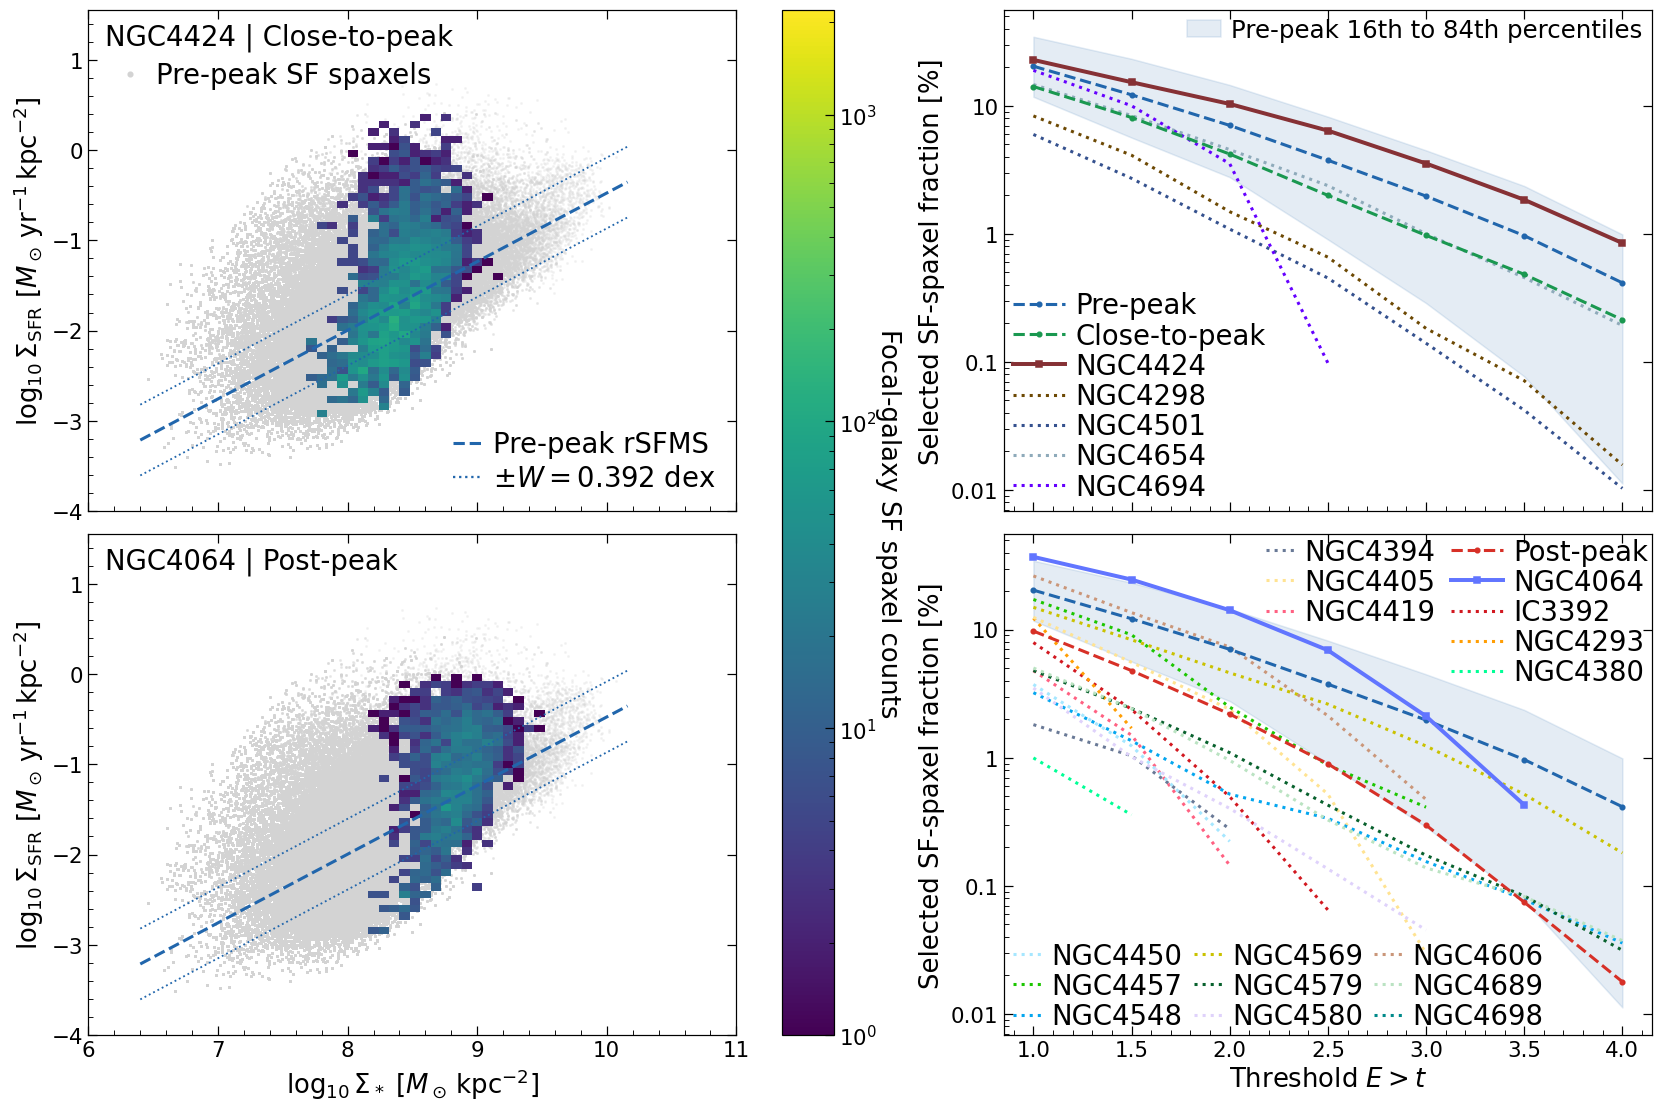

In [8]:
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

excess_comparison_ids = excess_tails.index[excess_tails.stage.isin([2, 3])]
assert all(g in GALAXY_COLORS for g in excess_comparison_ids), 'Missing fixed galaxy colors'

excess_plot_focals = tuple((galaxy, stage) for galaxy, stage in excess_focals
                           if galaxy != 'NGC4654')
fig_excess, axes_excess = plt.subplots(len(excess_plot_focals), 2, figsize=(15, 10),
    sharex='col', sharey='col', layout='constrained')
excess_pre_color = STAGE_COLORS[1]
excess_line_x = np.linspace(excess_x_edges[0], excess_x_edges[-1], 300)
excess_fit_y = pre_peak_fit['slope'] * excess_line_x + pre_peak_fit['intercept']
for row, (galaxy, stage) in enumerate(excess_plot_focals):
    focal_color = GALAXY_COLORS[galaxy]
    ax = axes_excess[row, 0]
    ax.scatter(sf_x[excess_pre_mask], sf_y[excess_pre_mask], s=1,
        color='lightgray', alpha=0.20, rasterized=True, zorder=1)
    mesh_excess = ax.pcolormesh(excess_x_edges, excess_y_edges,
        np.ma.masked_equal(excess_histograms[galaxy].T, 0), cmap='viridis',
        norm=excess_norm, shading='flat', rasterized=True, zorder=2)
    ax.plot(excess_line_x, excess_fit_y, color=excess_pre_color, ls='--', lw=2, zorder=3)
    for sign in (-1, 1):
        ax.plot(excess_line_x, excess_fit_y + sign*excess_width,
            color=excess_pre_color, ls=':', lw=1.2, zorder=3)
    ax.set(xlim=(6, 11), ylim=(-4, 1.55),
        ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [$M_\odot\,{\rm yr}^{-1}\,{\rm kpc}^{-2}$]')
    ax.text(0.025, 0.975, f'{galaxy} | {STAGE_LABELS[stage]}',
        transform=ax.transAxes, ha='left', va='top', fontsize=18)
    if row == 0:
        legend_style = dict(fontsize=18, frameon=False, handlelength=1.05,
            handletextpad=0.4, labelspacing=0.23, borderaxespad=0)
        spaxel_legend = ax.legend(handles=[
            Line2D([], [], color='lightgray', marker='.', ls='', label='Pre-peak SF spaxels'),
        ], loc='upper left', bbox_to_anchor=(0.025, 0.92), **legend_style)
        ax.add_artist(spaxel_legend)
        ax.legend(handles=[
            Line2D([], [], color=excess_pre_color, ls='--', lw=2, label='Pre-peak rSFMS'),
            Line2D([], [], color=excess_pre_color, ls=':', label=rf'$\pm W={excess_width:.3f}$ dex'),
        ], loc='lower right', bbox_to_anchor=(0.985, 0.015), **legend_style)
    ax = axes_excess[row, 1]
    pre_peak_band = ax.fill_between(excess_thresholds, 100*excess_pre_bounds[0], 100*excess_pre_bounds[1],
        where=excess_pre_bounds[0] > 0, color=excess_pre_color, alpha=0.12)
    same_stage = excess_tails.loc[excess_tails.stage.eq(stage)].drop(index=galaxy).sort_index()
    for other, record in same_stage.iterrows():
        ax.plot(excess_thresholds, 100*record.fractions, color=GALAXY_COLORS[other],
            ls=':', lw=2.0, alpha=1.0, label=other, zorder=2)
    for mean_stage in (1, stage):
        ax.plot(excess_thresholds, 100*excess_stage_means[mean_stage],
            color=STAGE_COLORS[mean_stage], ls='--', marker='o', ms=3, lw=2,
            label=(STAGE_LABELS[mean_stage]
                   if row == 0 or (stage == 3 and mean_stage == 3) else None), zorder=3)
    ax.plot(excess_thresholds, 100*excess_tails.loc[galaxy, 'fractions'],
        color=focal_color, ls='-', marker='s', ms=4, lw=2.6, label=galaxy, zorder=4)
    ax.set(xticks=excess_thresholds, ylabel='Selected SF-spaxel fraction [%]')
    handles, labels = ax.get_legend_handles_labels()
    n_highlighted = 3 if row == 0 else 2 if stage == 3 else 1
    handles = handles[-n_highlighted:] + handles[:-n_highlighted]
    labels = labels[-n_highlighted:] + labels[:-n_highlighted]
    legend_style = dict(borderaxespad=0, fontsize=18, frameon=False,
        columnspacing=0.4, handletextpad=0.35, labelspacing=0.08, borderpad=0.1)
    if stage == 3:
        # Stagger the upper columns to leave room for the descending curves.
        upper_right = ax.legend(handles[:5], labels[:5], loc='upper right',
            bbox_to_anchor=(0.998, 0.998), handlelength=1.9, **legend_style)
        ax.add_artist(upper_right)
        upper_inner = ax.legend(handles[5:8], labels[5:8], loc='upper right',
            bbox_to_anchor=(0.67, 0.998), handlelength=1.05, **legend_style)
        ax.add_artist(upper_inner)
        ax.legend(handles[8:], labels[8:], loc='lower left',
            bbox_to_anchor=(0.01, 0.004), ncol=3, handlelength=1.05, **legend_style)
    else:
        band_legend = ax.legend([pre_peak_band], ['Pre-peak 16th to 84th percentiles'],
            loc='upper right', bbox_to_anchor=(0.985, 0.985), fontsize=16, frameon=False,
            borderaxespad=0, borderpad=0, handlelength=1.4, handletextpad=0.4)
        ax.add_artist(band_legend)
        ax.legend(handles, labels, loc='lower left',
            bbox_to_anchor=(0.01, 0.015), handlelength=1.9, **legend_style)
# Shared fraction axes are logarithmic, with labels in ordinary percent units.
axes_excess[0, 1].set_yscale('log', nonpositive='mask')
for ax in axes_excess[:, 1::2].flat:
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
for ax in axes_excess.flat:
    ax.minorticks_on()
    ax.tick_params(top=True, right=True)
axes_excess[-1, 0].set_xlabel(r'$\log_{10}\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]')
axes_excess[-1, 1].set_xlabel(r'Threshold $E>t$')
excess_colorbar = fig_excess.colorbar(mesh_excess, ax=axes_excess[:, 0].tolist())
excess_colorbar.set_label('Focal-galaxy SF spaxel counts', rotation=270, labelpad=16)
plt.show()
plt.close(fig_excess)


### Cell 45 · Six close-to-peak and post-peak galaxies

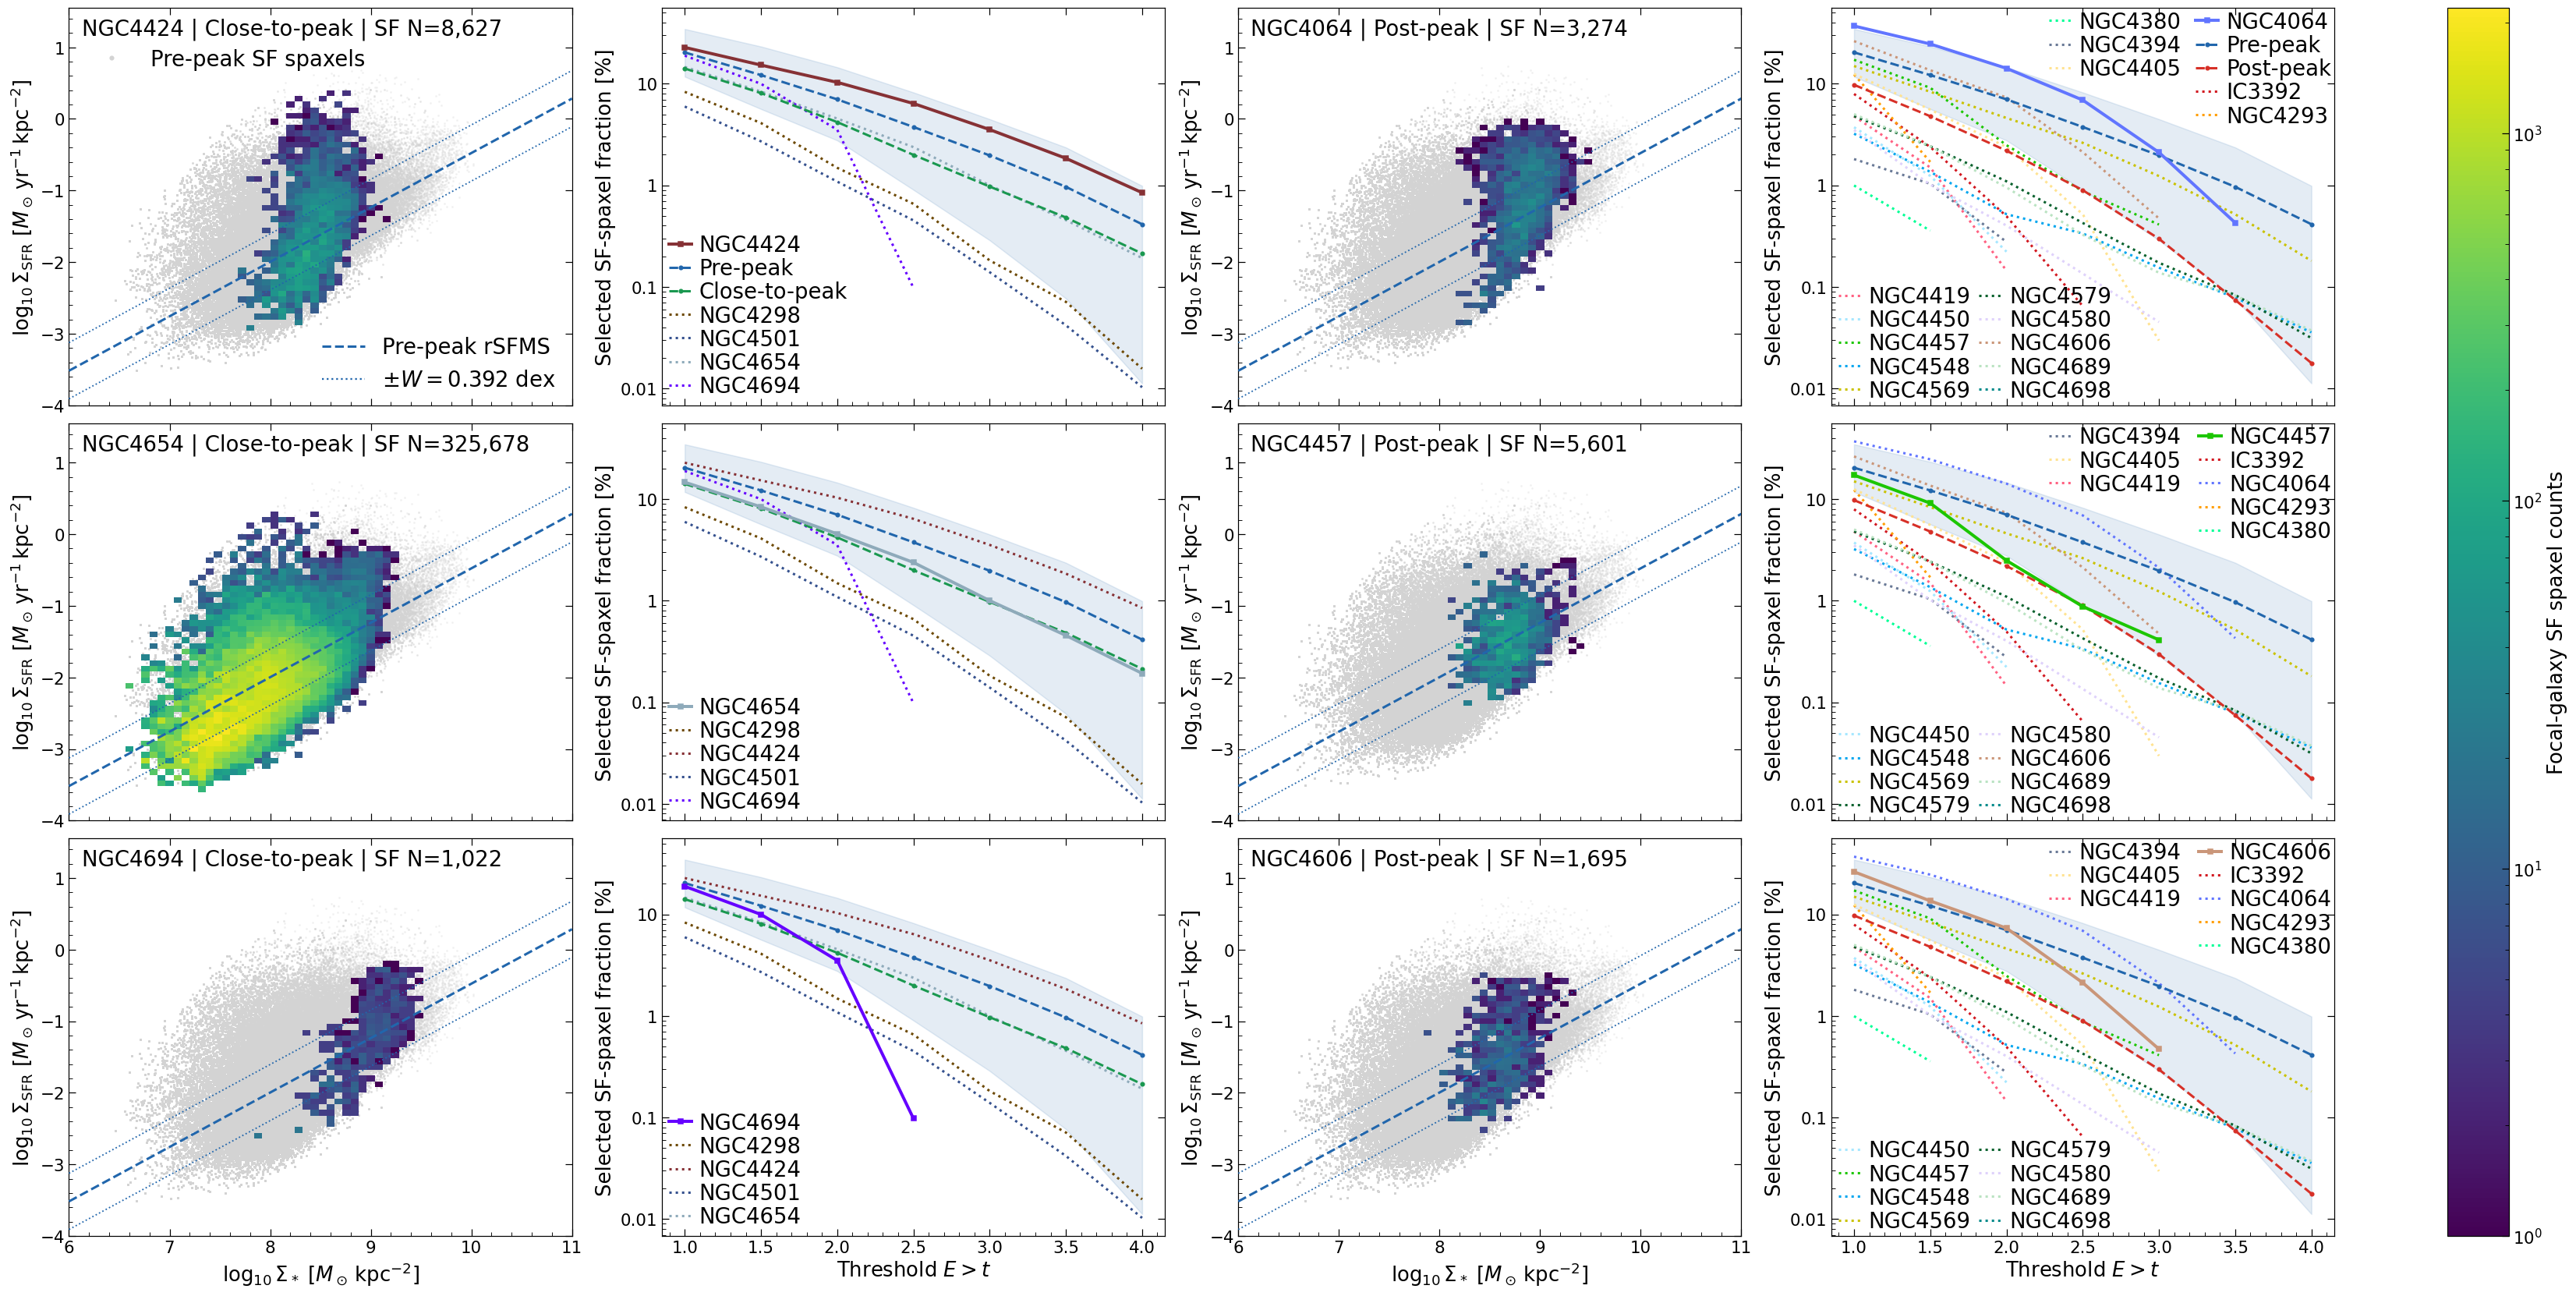

In [9]:
# Cell 44 diagnostics for three close-to-peak and three post-peak galaxies.
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

excess_grid_rows = (
    ('NGC4424', 'NGC4064'),
    ('NGC4654', 'NGC4457'),
    ('NGC4694', 'NGC4606'),
)
excess_grid_groups = {}
for pair in excess_grid_rows:
    for galaxy, stage in zip(pair, (2, 3)):
        match = excess_meta.index[excess_meta.galaxy.eq(galaxy)]
        if len(match) != 1 or galaxy not in excess_tails.index:
            raise ValueError(f'{galaxy}: missing from the selected SF sample')
        if int(excess_tails.loc[galaxy, 'stage']) != stage:
            raise ValueError(f'{galaxy}: unexpected catalogue stage')
        excess_grid_groups[galaxy] = match.item()

# Use the same bin width as cell 44 and cover all six focal samples.
excess_grid_selected = excess_pre_mask | np.isin(sf_group, list(excess_grid_groups.values()))
excess_grid_edges = [
    excess_bin_width * np.arange(
        np.floor(values[excess_grid_selected].min() / excess_bin_width),
        np.ceil(values[excess_grid_selected].max() / excess_bin_width) + 2,
    )
    for values in (sf_x, sf_y)
]
excess_grid_hist = {}
for galaxy, group_id in excess_grid_groups.items():
    selected = sf_group == group_id
    excess_grid_hist[galaxy] = np.histogram2d(
        sf_x[selected], sf_y[selected], bins=excess_grid_edges
    )[0]
excess_grid_norm = LogNorm(vmin=1, vmax=max(2, max(h.max() for h in excess_grid_hist.values())))

fig_excess_grid, axes_excess_grid = plt.subplots(
    3, 4, figsize=(30, 15), sharex='col', sharey='col', layout='constrained'
)
axes_excess_grid[0, 3].sharey(axes_excess_grid[0, 1])
excess_grid_pre_color = STAGE_COLORS[1]
excess_grid_line_x = np.linspace(6, 11, 300)
excess_grid_fit_y = pre_peak_fit['slope'] * excess_grid_line_x + pre_peak_fit['intercept']
for row, pair in enumerate(excess_grid_rows):
    for pair_index, (galaxy, stage) in enumerate(zip(pair, (2, 3))):
        ax_density, ax_tail = axes_excess_grid[row, 2 * pair_index:2 * pair_index + 2]
        focal_color = GALAXY_COLORS[galaxy]
        ax_density.scatter(sf_x[excess_pre_mask], sf_y[excess_pre_mask], s=1,
            color='lightgray', alpha=0.20, rasterized=True, zorder=1)
        mesh_excess_grid = ax_density.pcolormesh(*excess_grid_edges,
            np.ma.masked_equal(excess_grid_hist[galaxy].T, 0), cmap='viridis',
            norm=excess_grid_norm, shading='flat', rasterized=True, zorder=2)
        ax_density.plot(excess_grid_line_x, excess_grid_fit_y,
            color=excess_grid_pre_color, ls='--', lw=2, zorder=3)
        for sign in (-1, 1):
            ax_density.plot(excess_grid_line_x, excess_grid_fit_y + sign * excess_width,
                color=excess_grid_pre_color, ls=':', lw=1.2, zorder=3)
        ax_density.set(xlim=(6, 11), ylim=(-4, 1.55),
            ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [$M_\odot\,{\rm yr}^{-1}\,{\rm kpc}^{-2}$]')
        n_sf = int(excess_tails.loc[galaxy, 'N_SF'])
        ax_density.text(0.025, 0.975, f'{galaxy} | {STAGE_LABELS[stage]} | SF N={n_sf:,}',
            transform=ax_density.transAxes, ha='left', va='top', fontsize=18)
        if row == 0 and pair_index == 0:
            legend_style = dict(fontsize=18, frameon=False, borderaxespad=0)
            spaxel_legend = ax_density.legend(handles=[
                Line2D([], [], color='lightgray', marker='.', ls='', label='Pre-peak SF spaxels'),
            ], loc='upper left', bbox_to_anchor=(0.025, 0.92), **legend_style)
            ax_density.add_artist(spaxel_legend)
            ax_density.legend(handles=[
                Line2D([], [], color=excess_grid_pre_color, ls='--', lw=2, label='Pre-peak rSFMS'),
                Line2D([], [], color=excess_grid_pre_color, ls=':', label=rf'$\pm W={excess_width:.3f}$ dex'),
            ], loc='lower right', bbox_to_anchor=(0.985, 0.015), **legend_style)

        ax_tail.fill_between(excess_thresholds, 100 * excess_pre_bounds[0], 100 * excess_pre_bounds[1],
            where=excess_pre_bounds[0] > 0, color=excess_grid_pre_color, alpha=0.12)
        focal_line, = ax_tail.plot(excess_thresholds, 100 * excess_tails.loc[galaxy, 'fractions'],
            color=focal_color, ls='-', marker='s', ms=4, lw=2.6, label=galaxy, zorder=4)
        legend_lines = [focal_line]
        for mean_stage in (1, stage):
            mean_line, = ax_tail.plot(excess_thresholds, 100 * excess_stage_means[mean_stage],
                color=STAGE_COLORS[mean_stage], ls='--', marker='o', ms=3, lw=2,
                label=STAGE_LABELS[mean_stage], zorder=3)
            if row == 0:
                legend_lines.append(mean_line)
        same_stage = excess_tails.loc[excess_tails.stage.eq(stage)].drop(index=galaxy).sort_index()
        for other, record in same_stage.iterrows():
            other_line, = ax_tail.plot(excess_thresholds, 100 * record.fractions,
                color=GALAXY_COLORS[other], ls=':', lw=2, label=other, zorder=2)
            legend_lines.append(other_line)
        ax_tail.set(xticks=excess_thresholds, ylabel='Selected SF-spaxel fraction [%]')
        legend_style = dict(fontsize=18, frameon=False, handlelength=1.05,
            columnspacing=0.4, handletextpad=0.35, labelspacing=0.08, borderpad=0.1)
        if stage == 3:
            # Stagger the upper columns to leave room for the descending curves.
            upper_right = ax_tail.legend(handles=legend_lines[:5], loc='upper right',
                bbox_to_anchor=(0.998, 0.998), borderaxespad=0, **legend_style)
            ax_tail.add_artist(upper_right)
            upper_inner = ax_tail.legend(handles=legend_lines[5:8], loc='upper right',
                bbox_to_anchor=(0.70, 0.998), borderaxespad=0, **legend_style)
            ax_tail.add_artist(upper_inner)
            ax_tail.legend(handles=legend_lines[8:], loc='lower left',
                bbox_to_anchor=(0.01, 0.004), borderaxespad=0, ncol=2, **legend_style)
        else:
            ax_tail.legend(handles=legend_lines, loc='lower left',
                bbox_to_anchor=(0.01, 0.015), borderaxespad=0, **legend_style)

        if row == len(excess_grid_rows) - 1:
            ax_density.set_xlabel(r'$\log_{10}\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]')
            ax_tail.set_xlabel(r'Threshold $E>t$')

# Shared fraction axes are logarithmic, with labels in ordinary percent units.
axes_excess_grid[0, 1].set_yscale('log', nonpositive='mask')
for ax in axes_excess_grid[:, 1::2].flat:
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
for ax in axes_excess_grid.flat:
    ax.minorticks_on()
    ax.tick_params(top=True, right=True)
fig_excess_grid.colorbar(mesh_excess_grid, ax=axes_excess_grid,
    label='Focal-galaxy SF spaxel counts')
plt.show()
